In [1]:
print("Python is working")

Python is working


In [2]:
import os
import random
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

print("All libraries imported successfully.")

All libraries imported successfully.


In [3]:
df = pd.read_csv("train_labels.csv")

print("Dataset Loaded Successfully")
print("Dataset Shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


# Information tells us we have two columns, an image_id index for each corresponding image associated with each labelled class
# 63,660 images with labels

Dataset Loaded Successfully
Dataset Shape: (63660, 2)


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogFace
3,4,DogNose
4,5,DogNose



Column names:
['image_id', 'class']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 63660 entries, 0 to 63659
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   image_id  63660 non-null  int64
 1   class     63660 non-null  str  
dtypes: int64(1), str(1)
memory usage: 994.8 KB


In [4]:
class_counts = df["class"].value_counts().sort_index()

print("Number of images per class:")
display(class_counts.to_frame(name="Image Count"))

print("\nTotal labelled images:", len(df))
print("Number of classes:", df["class"].nunique())

class_percentages = (
    df["class"].value_counts(normalize=True).sort_index() * 100
)

class_summary = pd.DataFrame({
    "Image Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

display(class_summary)


# Is the dataset balanced? No, it is not
# Cat images have noticeably higher counts in every category

# 54.51% of all the images are of cats, a very slight imbalance but an imbalance nonetheless

Number of images per class:


,Image Count
class,
CatEye,13884
CatFace,6942
CatMouth,6942
CatNose,6942
DogEye,11580
DogFace,5790
DogMouth,5790
DogNose,5790



Total labelled images: 63660
Number of classes: 8


,Image Count,Percentage (%)
class,,
CatEye,13884,21.81
CatFace,6942,10.90
CatMouth,6942,10.90
CatNose,6942,10.90
DogEye,11580,18.19
DogFace,5790,9.10
DogMouth,5790,9.10
DogNose,5790,9.10


In [5]:
largest_class = class_counts.max()
smallest_class = class_counts.min()

print("Largest class:", largest_class)
print("Smallest class:", smallest_class)
print("Largest-to-smallest class ratio:", round(largest_class / smallest_class, 2))

# In this case, it is CatEye vs DogFace or DogMouth or DogNose
# We definitely have an imbalance in what classes are being represented

Largest class: 13884
Smallest class: 5790
Largest-to-smallest class ratio: 2.4


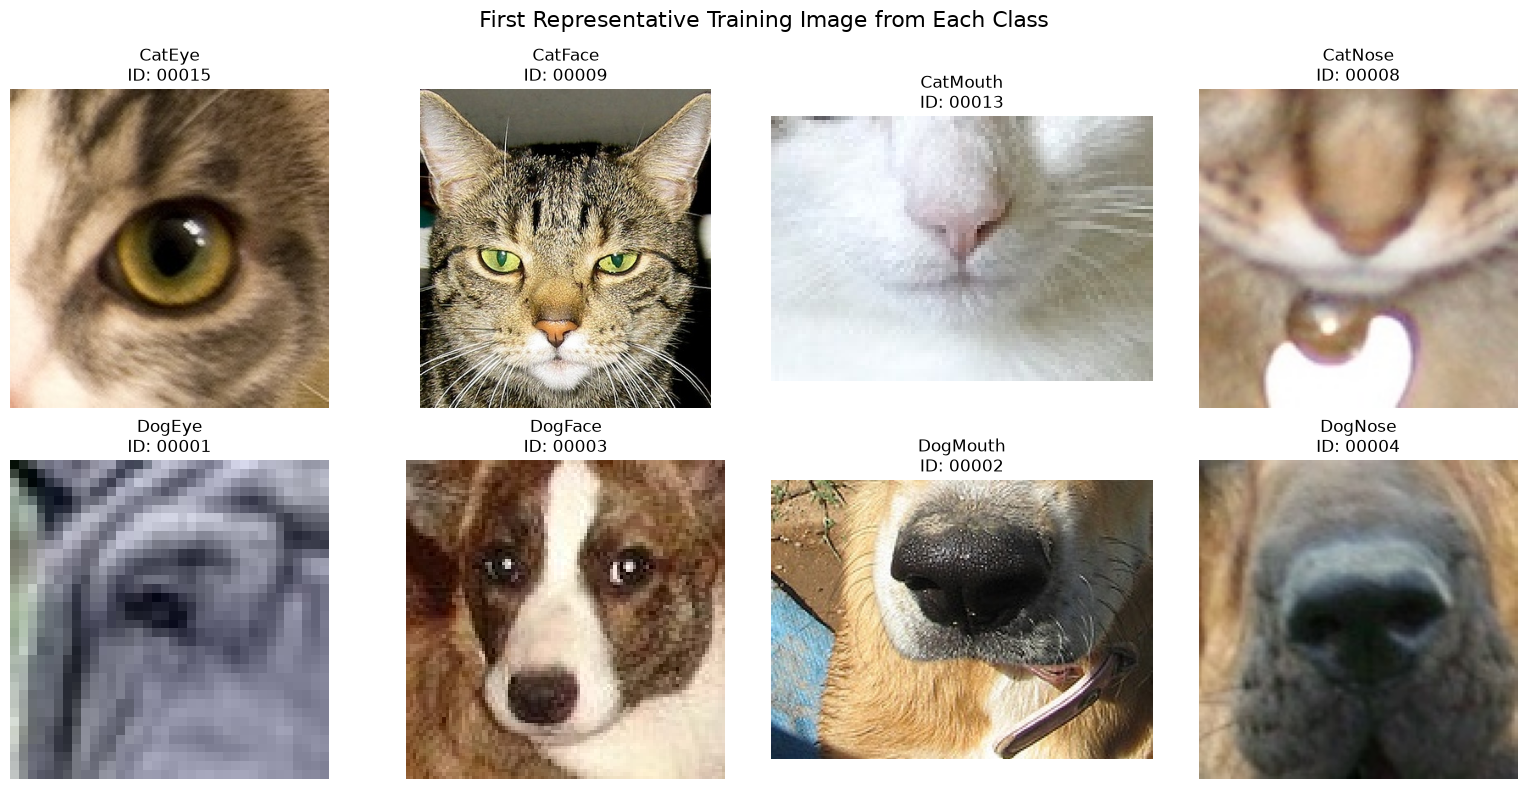

In [6]:
train_dir = "train"

first_images = df.drop_duplicates(subset="class").sort_values("class")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, (_, row) in zip(axes, first_images.iterrows()):

    image_id = int(row["image_id"])
    label = row["class"]

    image_path = os.path.join(
        train_dir,
        f"{image_id:05d}.jpg"
    )

    if os.path.exists(image_path):
        image = Image.open(image_path).convert("RGB")

        ax.imshow(image)
        ax.set_title(f"{label}\nID: {image_id:05d}")
    else:
        ax.set_title(f"{label}\nImage not found")
        print("Missing image:", image_path)

    ax.axis("off")

plt.suptitle("First Representative Training Image from Each Class", fontsize=16)
plt.tight_layout()
plt.show()


# Apparently image 00001 is of a dog's eye? I don't see it
# Image 00002 is apparently of a dog's mouth, I think it better represents a dog's nose.

In [7]:
train_files = [
    f for f in os.listdir("train")
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

test_files = [
    f for f in os.listdir("test")
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Training image files:", len(train_files))
print("Test image files:", len(test_files))
print("Training label rows:", len(df))


# We have 63,660 images with the same corresponding labels in classes
# And 29,443 images to test the trained machine on

Training image files: 63660
Test image files: 29443
Training label rows: 63660


In [8]:
from collections import Counter

image_dimensions = Counter()
corrupted_images = []

for filename in train_files:
    image_path = os.path.join(train_dir, filename)

    try:
        with Image.open(image_path) as image:
            image_dimensions[image.size] += 1
    except Exception as e:
        corrupted_images.append((filename, str(e)))

print("Most common image dimensions:")
for dimensions, count in image_dimensions.most_common(5):
    print(f"{dimensions}: {count} images")

print("\nNumber of corrupted or unreadable images:", len(corrupted_images))


if image_dimensions:
    largest_resolution = max(
        image_dimensions,
        key=lambda size: size[0] * size[1]
    )

    smallest_resolution = min(
        image_dimensions,
        key=lambda size: size[0] * size[1]
    )

    print("Largest resolution:", largest_resolution,
          f"- {largest_resolution[0] * largest_resolution[1]:,} pixels")
    print("Number of images:", image_dimensions[largest_resolution])

    print("\nSmallest resolution:", smallest_resolution,
          f"- {smallest_resolution[0] * smallest_resolution[1]:,} pixels")
    print("Number of images:", image_dimensions[smallest_resolution])
else:
    print("No readable images found.")

Most common image dimensions:
(40, 40): 1062 images
(48, 48): 1051 images
(42, 42): 1050 images
(38, 38): 1002 images
(44, 44): 1002 images

Number of corrupted or unreadable images: 0
Largest resolution: (2219, 2219) - 4,923,961 pixels
Number of images: 1

Smallest resolution: (4, 4) - 16 pixels
Number of images: 3


In [9]:
from pathlib import Path
from collections import defaultdict
import hashlib
import pandas as pd

train_dir = Path("train")  # Adjust if needed

hash_to_files = defaultdict(list)

for path in sorted(train_dir.glob("*.jpg")):
    digest = hashlib.md5(path.read_bytes()).hexdigest()
    hash_to_files[digest].append(path.name)

duplicate_groups = [
    files for files in hash_to_files.values()
    if len(files) > 1
]

duplicate_file_count = sum(
    len(files) for files in duplicate_groups
)

print("Images checked:", sum(
    len(files) for files in hash_to_files.values()
))
print("Exact duplicate groups:", len(duplicate_groups))
print("Files belonging to duplicate groups:", duplicate_file_count)

for group in duplicate_groups[:10]:
    print(group)


labels_df = pd.read_csv("train_labels.csv")

# Map image filenames to their official labels
label_map = {
    f"{int(row.image_id):05d}.jpg": row["class"]
    for _, row in labels_df.iterrows()
}

conflicting_groups = []

for group in duplicate_groups:
    group_labels = {label_map[name] for name in group}
    status = "SAME LABEL" if len(group_labels) == 1 else "CONFLICTING LABELS"

    print(f"{status}: {group}")
    print("  Labels:", {
        name: label_map[name] for name in group
    })

    if len(group_labels) > 1:
        conflicting_groups.append(group)

print("\nGroups with conflicting labels:", len(conflicting_groups))


Images checked: 63660
Exact duplicate groups: 15
Files belonging to duplicate groups: 30
['00356.jpg', '06903.jpg']
['03365.jpg', '42280.jpg']
['03926.jpg', '56008.jpg']
['04003.jpg', '46057.jpg']
['07219.jpg', '12150.jpg']
['13090.jpg', '63140.jpg']
['16730.jpg', '21960.jpg']
['25436.jpg', '40256.jpg']
['30201.jpg', '50179.jpg']
['33473.jpg', '59020.jpg']
SAME LABEL: ['00356.jpg', '06903.jpg']
  Labels: {'00356.jpg': 'CatEye', '06903.jpg': 'CatEye'}
SAME LABEL: ['03365.jpg', '42280.jpg']
  Labels: {'03365.jpg': 'CatEye', '42280.jpg': 'CatEye'}
SAME LABEL: ['03926.jpg', '56008.jpg']
  Labels: {'03926.jpg': 'CatEye', '56008.jpg': 'CatEye'}
SAME LABEL: ['04003.jpg', '46057.jpg']
  Labels: {'04003.jpg': 'DogEye', '46057.jpg': 'DogEye'}
SAME LABEL: ['07219.jpg', '12150.jpg']
  Labels: {'07219.jpg': 'CatMouth', '12150.jpg': 'CatMouth'}
SAME LABEL: ['13090.jpg', '63140.jpg']
  Labels: {'13090.jpg': 'CatEye', '63140.jpg': 'CatEye'}
SAME LABEL: ['16730.jpg', '21960.jpg']
  Labels: {'16730.jpg'

In [10]:

from pathlib import Path
import hashlib
import pandas as pd

train_dir = Path("train")
labels_df = pd.read_csv("train_labels.csv").copy()

labels_df["filename"] = labels_df["image_id"].apply(
    lambda image_id: f"{int(image_id):05d}.jpg"
)

labels_df["image_hash"] = labels_df["filename"].apply(
    lambda filename: hashlib.md5(
        (train_dir / filename).read_bytes()
    ).hexdigest()
)

label_counts = labels_df.groupby("image_hash")["class"].nunique()
assert (label_counts <= 1).all(), "Conflicting labels found!"

deduplicated_df = labels_df.drop_duplicates(
    subset="image_hash",
    keep="first"
).copy()

print("Original rows:", len(labels_df))
print("Rows after deduplication:", len(deduplicated_df))
print("Rows removed:", len(labels_df) - len(deduplicated_df))


Original rows: 63660
Rows after deduplication: 63645
Rows removed: 15


In [11]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    device = torch.device("cuda")
else:
    raise RuntimeError(
        "CUDA is unavailable. Check your PyTorch installation and NVIDIA driver."
    )

print("PyTorch version:", torch.__version__)
print("Torchvision version:", __import__("torchvision").__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA runtime:", torch.version.cuda)
print("Selected device:", device)

PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 3070
CUDA runtime: 12.8
Selected device: cuda


In [12]:
ROOT_DIR = Path.cwd()

LABELS_PATH = ROOT_DIR / "train_labels.csv"
TRAIN_DIR = ROOT_DIR / "train"
TEST_DIR = ROOT_DIR / "test"

IMAGE_SIZE = 128
BATCH_SIZE = 64
NUM_CLASSES = 8
VALIDATION_SIZE = 0.20

print("Project directory:", ROOT_DIR)
print("Labels file exists:", LABELS_PATH.is_file())
print("Training directory exists:", TRAIN_DIR.is_dir())
print("Test directory exists:", TEST_DIR.is_dir())

# I am fortunate enough to have an RTX 3070 to run CUDA on

Project directory: c:\Users\Baller\Desktop\ENGE707-2026-Kaggle-Team-Loning
Labels file exists: True
Training directory exists: True
Test directory exists: True


In [13]:
df = pd.read_csv(LABELS_PATH)

print("\nColumn names:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())

print("\nUnique class names:")
print(sorted(df["class"].unique()))


Column names: ['image_id', 'class']

Missing values:
image_id    0
class       0
dtype: int64

Unique class names:
['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']


In [14]:
classes = sorted(df["class"].unique())

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(classes)
}

idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

df["label"] = df["class"].map(class_to_idx)

print("Class-to-index mapping:")
print(class_to_idx)

print("\nEncoded dataset:")
display(df.head())

assert len(classes) == NUM_CLASSES
assert df["label"].notna().all()
assert df["label"].between(0, NUM_CLASSES - 1).all()

Class-to-index mapping:
{'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}

Encoded dataset:


,image_id,class,label
0,1,DogEye,4
1,2,DogMouth,6
2,3,DogFace,5
3,4,DogNose,7
4,5,DogNose,7


In [15]:
train_df, val_df = train_test_split(
    df,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    stratify=df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

print("\nTraining class proportions:")
print(train_df["class"].value_counts(normalize=True).sort_index().round(3))

print("\nValidation class proportions:")
print(val_df["class"].value_counts(normalize=True).sort_index().round(3))

Training samples: 50928
Validation samples: 12732

Training class proportions:
class
CatEye      0.218
CatFace     0.109
CatMouth    0.109
CatNose     0.109
DogEye      0.182
DogFace     0.091
DogMouth    0.091
DogNose     0.091
Name: proportion, dtype: float64

Validation class proportions:
class
CatEye      0.218
CatFace     0.109
CatMouth    0.109
CatNose     0.109
DogEye      0.182
DogFace     0.091
DogMouth    0.091
DogNose     0.091
Name: proportion, dtype: float64


In [16]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor()
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

In [17]:
class PetFeatureDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_id = int(row["image_id"])
        image_path = self.image_dir / f"{image_id:05d}.jpg"

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = int(row["label"])

        return image, label

In [18]:
train_dataset = PetFeatureDataset(
    train_df,
    TRAIN_DIR,
    transform=train_transform
)

val_dataset = PetFeatureDataset(
    val_df,
    TRAIN_DIR,
    transform=eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 796
Validation batches: 199


In [19]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image tensor dtype:", images.dtype)
print("Label tensor dtype:", labels.dtype)
print("CPU batch device:", images.device)

images = images.to(device, non_blocking=True)
labels = labels.to(device, non_blocking=True)

print("\nAfter transfer:")
print("Image batch device:", images.device)
print("Label batch device:", labels.device)
print("Pixel range:", images.min().item(), "to", images.max().item())

assert images.is_cuda
assert labels.is_cuda
assert images.shape == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
assert labels.min().item() >= 0
assert labels.max().item() < NUM_CLASSES

Image batch shape: torch.Size([64, 3, 128, 128])
Label batch shape: torch.Size([64])
Image tensor dtype: torch.float32
Label tensor dtype: torch.int64
CPU batch device: cpu

After transfer:
Image batch device: cuda:0
Label batch device: cuda:0
Pixel range: 0.0 to 1.0


In [20]:
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_df["label"].to_numpy()
)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

print("Class weights on:", class_weights.device)

for idx, weight in enumerate(class_weights.cpu().tolist()):
    print(f"{idx_to_class[idx]}: {weight:.4f}")

Class weights on: cuda:0
CatEye: 0.5732
CatFace: 1.1462
CatMouth: 1.1462
CatNose: 1.1464
DogEye: 0.6872
DogFace: 1.3744
DogMouth: 1.3744
DogNose: 1.3744


In [21]:
class PetFeatureCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1: 3 -> 32 feature maps
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 2: 32 -> 64 feature maps
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 3: 64 -> 128 feature maps
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


model = PetFeatureCNN(num_classes=NUM_CLASSES).to(device)

print(model)
print("\nModel device:", next(model.parameters()).device)

PetFeatureCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
   

In [22]:
model.eval()

with torch.no_grad():
    sample_images, sample_labels = next(iter(val_loader))
    sample_images = sample_images.to(device)

    sample_outputs = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", sample_outputs.shape)
print("Output device:", sample_outputs.device)

assert sample_outputs.shape == (sample_images.shape[0], NUM_CLASSES)
assert sample_outputs.is_cuda

model.train()

Input shape: torch.Size([64, 3, 128, 128])
Output shape: torch.Size([64, 8])
Output device: cuda:0


PetFeatureCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
   

In [23]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001


In [24]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear gradients from the previous batch
        optimizer.zero_grad(set_to_none=True)

        # Forward propagation
        outputs = model(images)

        # Calculate weighted classification loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update the model's parameters
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    # No gradients or parameter updates during validation
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += batch_size

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

In [25]:
EPOCHS = 10

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy = -1.0
best_model_path = ROOT_DIR / "best_cnn.pth"

for epoch in range(EPOCHS):
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_accuracy": val_accuracy,
                "class_to_idx": class_to_idx,
                "image_size": IMAGE_SIZE
            },
            best_model_path
        )

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2%}"
    )

print("\nBest validation accuracy:", f"{best_val_accuracy:.2%}")
print("Best checkpoint saved to:", best_model_path)

Epoch 01/10 | Train Loss: 1.5922 | Train Acc: 37.54% | Val Loss: 1.8765 | Val Acc: 31.22%
Epoch 02/10 | Train Loss: 1.3263 | Train Acc: 49.17% | Val Loss: 1.4500 | Val Acc: 41.28%
Epoch 03/10 | Train Loss: 1.1591 | Train Acc: 56.52% | Val Loss: 1.1469 | Val Acc: 56.77%
Epoch 04/10 | Train Loss: 1.0428 | Train Acc: 61.38% | Val Loss: 0.8954 | Val Acc: 66.13%
Epoch 05/10 | Train Loss: 0.9617 | Train Acc: 64.69% | Val Loss: 1.0597 | Val Acc: 63.32%
Epoch 06/10 | Train Loss: 0.9206 | Train Acc: 66.55% | Val Loss: 0.7861 | Val Acc: 72.47%
Epoch 07/10 | Train Loss: 0.8721 | Train Acc: 68.53% | Val Loss: 0.8256 | Val Acc: 72.99%
Epoch 08/10 | Train Loss: 0.8317 | Train Acc: 70.04% | Val Loss: 0.8605 | Val Acc: 69.18%
Epoch 09/10 | Train Loss: 0.8000 | Train Acc: 71.40% | Val Loss: 0.7148 | Val Acc: 73.01%
Epoch 10/10 | Train Loss: 0.7789 | Train Acc: 72.13% | Val Loss: 0.8618 | Val Acc: 66.70%

Best validation accuracy: 73.01%
Best checkpoint saved to: c:\Users\Baller\Desktop\ENGE707-2026-Kag

In [26]:
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Restored epoch:", checkpoint["epoch"])
print("Saved validation accuracy:", f'{checkpoint["val_accuracy"]:.2%}')

Restored epoch: 9
Saved validation accuracy: 73.01%


In [27]:
from sklearn.metrics import classification_report, confusion_matrix

all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.tolist())

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=[idx_to_class[i] for i in range(NUM_CLASSES)],
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

      CatEye     0.9744    0.6442    0.7756      2777
     CatFace     0.9563    0.8523    0.9013      1388
    CatMouth     0.6753    0.8437    0.7502      1388
     CatNose     0.6719    0.7401    0.7044      1389
      DogEye     0.6796    0.6136    0.6449      2316
     DogFace     0.6422    0.8325    0.7251      1158
    DogMouth     0.5757    0.8929    0.7001      1158
     DogNose     0.7001    0.6088    0.6513      1158

    accuracy                         0.7301     12732
   macro avg     0.7345    0.7535    0.7316     12732
weighted avg     0.7618    0.7301    0.7322     12732



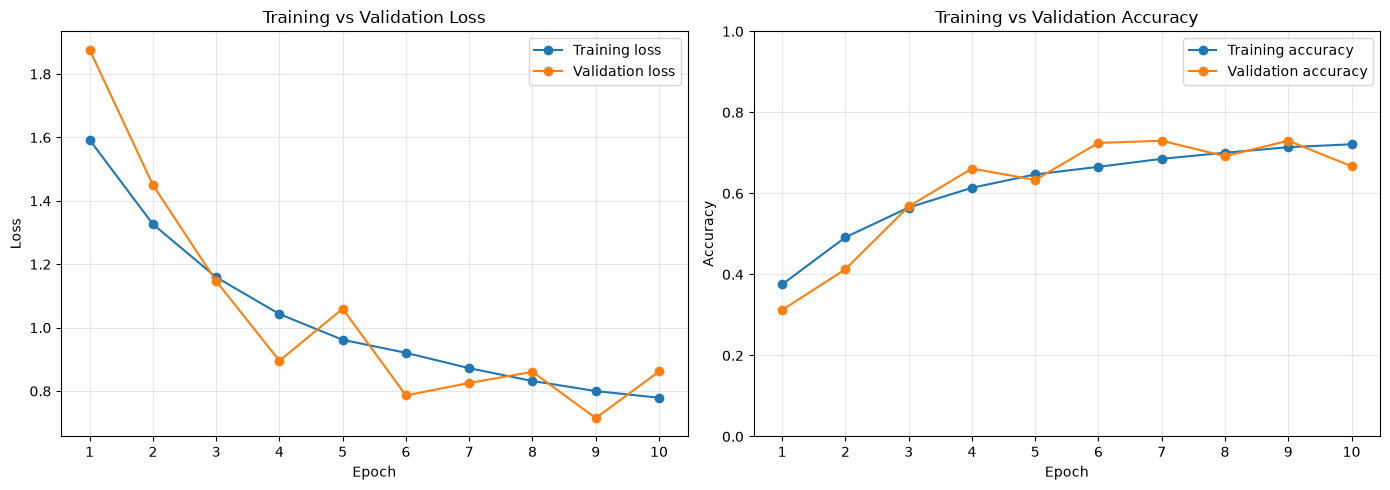

In [28]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(epochs, history["train_loss"], marker="o",
             label="Training loss")
axes[0].plot(epochs, history["val_loss"], marker="o",
             label="Validation loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(list(epochs))
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curves
axes[1].plot(epochs, history["train_accuracy"], marker="o",
             label="Training accuracy")
axes[1].plot(epochs, history["val_accuracy"], marker="o",
             label="Validation accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(list(epochs))
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()